In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import statsmodels.formula.api as smf

from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, roc_curve, recall_score, precision_recall_curve, auc, average_precision_score
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix, precision_score, hamming_loss
from sklearn.metrics import brier_score_loss

import copy
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

In [15]:
import pickle
with open('balanced_data.pkl', 'rb') as b:
    data = pickle.load(b)

X_res_sk = data['X_res_stroke']
y_res_sk = data['y_res_stroke']
X_res_db = data['X_res_diab']
y_res_db = data['y_res_diab']
X_res_cn = data['X_res_can']
y_res_cn = data['y_res_can']       
X_res_ha = data['X_res_ha']
y_res_ha = data['y_res_ha']    

X_val = data['X_val'] 
y_val = data['y_val']   

X_test = data['X_test']
y_test = data['y_test']

X_bal=data['X_bal']
y_bal=data['y_bal']
    

In [16]:
y_test=y_test.rename(columns=
              {'heart_attack' : 'HA'})
y_bal=y_bal.rename(columns=
              {'heart_attack' : 'HA'})
y_val=y_val.rename(columns=
              {'heart_attack' : 'HA'})

In [17]:

scaler = MinMaxScaler()
X_train_st = scaler.fit_transform(X_bal)
X_val_st   = scaler.transform(X_val)
X_test_st = scaler.transform(X_test)

x_train_t = torch.tensor(X_train_st, dtype=torch.float32)
y_train_t = torch.tensor(y_bal.values, dtype=torch.float32)

x_val_t   = torch.tensor(X_val_st, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32)

x_test_t  = torch.tensor(X_test_st, dtype=torch.float32)

In [18]:
def youden_threshold(y_true_col, y_prob_col):
    fpr, tpr, thresholds = roc_curve(y_true_col, y_prob_col)
    return thresholds[np.argmax(tpr - fpr)]

***MULTI_TASK LOGISTIC*** 

In [ ]:


class MultitaskLogistic(nn.Module):
    def __init__(self, n_features, n_outputs):
        super().__init__() 
        self.linear = nn.Linear(n_features, n_outputs) 
        
    def forward(self, x): 
        return self.linear(x) 
    
n_features = X_train_st.shape[1]
n_outputs  = y_bal.shape[1]

pos_weight = torch.tensor([
    (y_bal[col] == 0).sum() / (y_bal[col] == 1).sum()
    for col in y_bal.columns
], dtype=torch.float32)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

In [20]:
torch.manual_seed(1234)

lambdas    = np.logspace(-5, -2, 6)
n_epochs   = 1000
n_restarts = 5
lr         = 0.001
tuning_results = []

for lam in lambdas:
    best_misc  = np.inf
    best_model = None

    for h in range(n_restarts):
        model     = MultitaskLogistic(n_features, n_outputs)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=lam)

        for epoch in range(n_epochs):
            model.train()
            optimizer.zero_grad()
            loss = criterion(model(x_train_t), y_train_t)
            loss.backward()
            optimizer.step()

        # Best restart by validation misclassification
        model.eval()
        with torch.no_grad():
            y_prob_val_h = torch.sigmoid(model(x_val_t)).numpy()

        errors_h = []
        for i, col in enumerate(y_val.columns):
            thr      = youden_threshold(y_val[col].values, y_prob_val_h[:, i])
            y_pred_i = (y_prob_val_h[:, i] >= thr).astype(int)
            errors_h.append((y_pred_i != y_val[col].values).mean())
        misc_h = np.mean(errors_h)

        if misc_h < best_misc:
            best_misc  = misc_h
            best_model = copy.deepcopy(model)

    best_model.eval()
    with torch.no_grad():
        y_prob_val = torch.sigmoid(best_model(x_val_t)).numpy()

    errors = []
    for i, col in enumerate(y_val.columns):
        thr      = youden_threshold(y_val[col].values, y_prob_val[:, i])
        y_pred_i = (y_prob_val[:, i] >= thr).astype(int)
        errors.append((y_pred_i != y_val[col].values).mean())
    misclass = np.mean(errors)

    print(f"lambda={lam:.2e}  misc={misclass:.4f}")
    tuning_results.append((lam, misclass))

best_lambda = min(tuning_results, key=lambda x: x[1])[0]
print(f"\nMiglior lambda={best_lambda:.2e}")

lambda=1.00e-05  misc=0.3310
lambda=3.98e-05  misc=0.3734
lambda=1.58e-04  misc=0.3449
lambda=6.31e-04  misc=0.3476
lambda=2.51e-03  misc=0.3299
lambda=1.00e-02  misc=0.3569

Miglior lambda=2.51e-03


In [ ]:
best_misc_final  = np.inf
best_model_final = None
torch.manual_seed(1234)

for h in range(n_restarts):
    model     = MultitaskLogistic(n_features, n_outputs)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=best_lambda)

    for epoch in range(n_epochs):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(x_train_t), y_train_t)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        y_prob_val_h = torch.sigmoid(model(x_val_t)).numpy()

    errors_h = []
    for i, col in enumerate(y_val.columns):
        thr      = youden_threshold(y_val[col].values, y_prob_val_h[:, i])
        y_pred_i = (y_prob_val_h[:, i] >= thr).astype(int)
        errors_h.append((y_pred_i != y_val[col].values).mean())
    misc_h = np.mean(errors_h)

    if misc_h < best_misc_final:
        best_misc_final  = misc_h
        best_model_final = copy.deepcopy(model)

print(f'Best misc finale: {best_misc_final:.4f}')

Best misc finale: 0.3209


***MODEL EVALUATION***

In [ ]:
best_model_final.eval()
with torch.no_grad():
    y_prob_val = torch.sigmoid(best_model_final(x_val_t)).numpy()


best_thresholds={}
for i, col in enumerate(y_val.columns):
    fpr,tpr,thresholds=roc_curve(y_val[col],y_prob_val[:,i])
    best_tr = thresholds[np.argmax(tpr-fpr)]
    best_thresholds[col] = best_tr
    print(f'{col} thresholds: {best_tr}')

best_model_final.eval()
with torch.no_grad():
    y_prob = torch.sigmoid(best_model_final(x_test_t)).numpy()
    
results = {}
for i, col in enumerate(y_test.columns):
    y_pred_i = (y_prob[:,i] >= best_thresholds[col]).astype(int)
    
    precision, recall, _ = precision_recall_curve(y_test[col].values, y_prob[:,i])
                                                  
                                                  
    results[col] = {
        "f1": f1_score(y_test[col], y_pred_i),
        'precision': precision_score(y_test[col],y_pred_i),
        "auc": roc_auc_score(y_test[col], y_prob[:, i]),
        "misc": (y_pred_i != y_test[col].values).mean(),
        'sens' : recall_score(y_test[col].values, y_pred_i),
        'auc-pr' : auc(recall,precision),
        "confusion": confusion_matrix(y_test[col], y_pred_i),
        "brier": brier_score_loss(y_test[col].values, y_prob[:, i]),
        'threshold' : best_thresholds[col]
    }
       

y_pred_multi = np.zeros_like(y_test.values)
for i, col in enumerate(y_test.columns):
    y_pred_multi[:, i] = (y_prob[:, i] >= best_thresholds[col]).astype(int)

macro_f1 = f1_score(y_test.values, y_pred_multi, average='macro')
hamming = hamming_loss(y_test.values, y_pred_multi)

results["MacroF1"] = macro_f1
results["Hamming"] = hamming

brier_mean = np.mean([
    brier_score_loss(y_test[col].values, y_prob[:, i])
    for i, col in enumerate(y_test.columns)
])
results["Brier_mean"] = brier_mean


macro_auc = np.mean([
    roc_auc_score(y_test[col].values, y_prob[:, i])
    for i, col in enumerate(y_test.columns)
])
macro_auc_pr = np.mean([
    average_precision_score(y_test[col].values, y_prob[:, i])
    for i, col in enumerate(y_test.columns)
])

results["MacroAUC"] = macro_auc
results["MacroAUC_PR"] = macro_auc_pr

print(pd.DataFrame({k: v for k, v in results.items() if k != "confusion"}).T)

diabetes thresholds: 0.4965793788433075
stroke thresholds: 0.4955366551876068
HA thresholds: 0.5003137588500977
cancer thresholds: 0.5069388747215271
                   f1 precision       auc      misc      sens    auc-pr  \
diabetes     0.409891  0.282986  0.782399  0.305357  0.743161  0.346681   
stroke        0.11682  0.063717  0.731169  0.354153  0.701299  0.100381   
HA           0.329954  0.220715  0.742459  0.315333  0.653285  0.269485   
cancer       0.130617  0.074049  0.670022  0.314682  0.553299  0.074991   
MacroF1       0.24682   0.24682   0.24682   0.24682   0.24682   0.24682   
Hamming      0.322381  0.322381  0.322381  0.322381  0.322381  0.322381   
Brier_mean   0.224801  0.224801  0.224801  0.224801  0.224801  0.224801   
MacroAUC     0.731512  0.731512  0.731512  0.731512  0.731512  0.731512   
MacroAUC_PR  0.199336  0.199336  0.199336  0.199336  0.199336  0.199336   

                              confusion     brier threshold  
diabetes     [[2714, 1239], [169, 489

In [ ]:
def expected_calibration_error(y_true, y_prob, n_bins=10):
    quantiles = np.percentile(y_prob, np.linspace(0, 100, n_bins + 1))
    ece = 0
    n = len(y_prob)
    for b in range(n_bins):
        mask = (y_prob >= quantiles[b]) & (y_prob < quantiles[b+1])
        if mask.sum() > 0:
            acc = y_true[mask].mean()   
            conf = y_prob[mask].mean()  
            ece += mask.mean() * abs(acc - conf)
    return ece

for i, col in enumerate(y_test.columns):
    ece = expected_calibration_error(
        y_test[col].values, 
        y_prob[:, i]
    )
    print(f'{col}: ECE = {ece:.4f}')
    results[col]["ece"] = ece



diabetes: ECE = 0.3263
stroke: ECE = 0.4415
HA: ECE = 0.3477
cancer: ECE = 0.4442


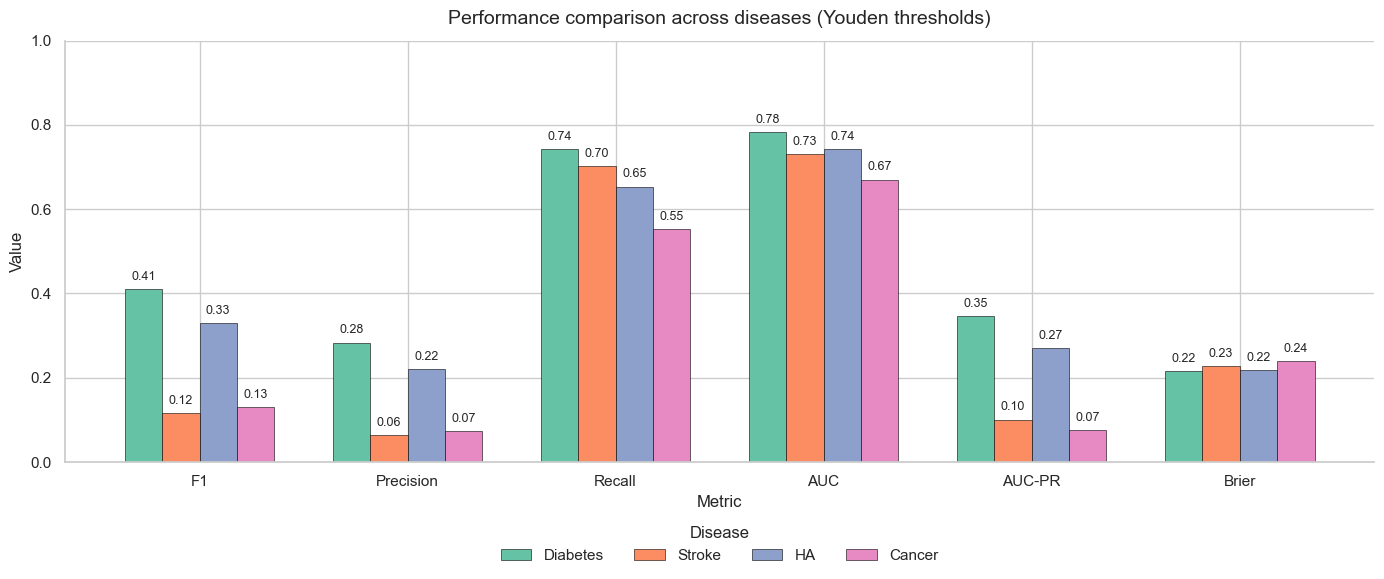

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

diseases = ['Diabetes', 'Stroke', 'HA', 'Cancer']

metric_map = {
    'F1'        : 'f1',
    'Precision' : 'precision',
    'Recall'    : 'sens',
    'AUC'       : 'auc',
    'AUC-PR'    : 'auc-pr',
    'Brier'     : 'brier'
}

metrics = list(metric_map.keys())

metric_df = pd.DataFrame({
    'Diabetes': [results['diabetes'][metric_map[m]] for m in metrics],
    'Stroke'  : [results['stroke'][metric_map[m]]   for m in metrics],
    'HA'      : [results['HA'][metric_map[m]]       for m in metrics],
    'Cancer'  : [results['cancer'][metric_map[m]]   for m in metrics],
}, index=metrics)

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False
    }
)

palette = sns.color_palette("Set2", 4)


x = np.arange(len(metrics))
width = 0.18

fig, ax = plt.subplots(figsize=(14, 6))

for i, disease in enumerate(metric_df.columns):
    bars = ax.bar(
        x + i * width,
        metric_df[disease].values,
        width=width,
        label=disease,
        color=palette[i],
        edgecolor='black',
        linewidth=0.4
    )

    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.015,
            f"{h:.2f}",
            ha='center',
            va='bottom',
            fontsize=9
        )


ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_ylabel("Value")
ax.set_xlabel("Metric")

ax.set_title(
    "Performance comparison across diseases (Youden thresholds)",
    fontsize=14,
    pad=12
)

ax.legend(
    title="Disease",
    ncol=4,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12)
)

plt.tight_layout()
plt.show()

In [26]:
import pickle

with open("results_mtl.pkl", "wb") as f:
    pickle.dump(results, f)